# Build a Language Model from Scratch

In this notebook we will build **every piece** of a GPT-style language model yourself:

**tokenizer → transformer → loss → optimizer → training loop → text generation**

Then you'll train it on your laptop's CPU, using TinyStories (a dataset of simple children's stories), and watch it go from random gibberish to writing its own little stories.

The architecture is the same as modern LLMs like LLaMA: pre-norm Transformer blocks, RMSNorm, SwiGLU, rotary position embeddings (RoPE), AdamW and a cosine learning-rate schedule. The only real difference is **size**. LLaMA-3 has 8 *billion* parameters. Ours has about 1.4 *million*.


| | Part | What you build |
|---|---|---|
| **Session 1** | 0 | Setup and data |
| | 1 | Tokenizer: text → bytes → BPE → token ids |
| | 2 | Building blocks: Linear, Embedding, RMSNorm, SwiGLU, softmax, and the idea behind RoPE |
| | - | **Homework: implement RoPE** |
| **Session 2** | 3 | Attention: scaled dot-product, causal mask, multi-head |
| | 4 | The full Transformer language model |
| | 5 | Training ingredients: cross-entropy, AdamW, LR schedule, gradient clipping, data loading |
| | 6 | Generating text: temperature and top-p sampling |
| | 7 | **Train it!** |

**How to use this notebook:** run cells from top to bottom with `Shift + Enter`, and read the text as you go. Cells marked ✅ are *checks*: they test that what you just built works.


---
# Part 0 — Setup

You need four packages: `torch`, `numpy`, `regex` and `matplotlib`. If you haven't installed them yet, uncomment the line below and run it once.

In [1]:
%pip install torch numpy regex matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import json
import math
import os
import time
import urllib.request
from collections import Counter, defaultdict
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np
import regex as re   # like Python's built-in `re`, but it understands Unicode classes such as \p{L} ("any letter")
import torch
import torch.nn as nn

torch.manual_seed(1337)
np.random.seed(1337)

DEVICE = "cpu"   # we are using a CPU, but if you access to GPUs, better!
DATA_DIR = "data"
CKPT_DIR = "checkpoints"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(CKPT_DIR, exist_ok=True)

print(f"PyTorch {torch.__version__} | using {torch.get_num_threads()} CPU threads")

PyTorch 2.14.1 | using 4 CPU threads


### The data: TinyStories

[TinyStories](https://arxiv.org/abs/2305.07759) is a collection of short stories written with the vocabulary of a 3–4 year old. Even *very* small models can learn to write fluent English if the language is simple enough, which makes a perfect for training on a personal laptop. 

The full training set is 2 GB. We'll only download the **validation file** (~22 MB, about 27,000 stories) and use it as our whole dataset, keeping 90% for training and 10% for validation.

In [3]:
DATA_URL = "https://huggingface.co/datasets/roneneldan/TinyStories/resolve/main/TinyStoriesV2-GPT4-valid.txt"
DATA_PATH = os.path.join(DATA_DIR, "TinyStoriesV2-GPT4-valid.txt")

if not os.path.exists(DATA_PATH):
    print("Downloading TinyStories (~22 MB)...")
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

with open(DATA_PATH, encoding="utf-8") as f:
    raw_text = f.read()

stories = raw_text.split("<|endoftext|>")
print(f"{len(raw_text):,} characters, {len(stories):,} stories\n")
print("First story:\n" + "-" * 60)
print(stories[0].strip())

22,493,387 characters, 27,631 stories

First story:
------------------------------------------------------------
u don't have to be scared of the loud dog, I'll protect you". The mole felt so safe with the little girl. She was very kind and the mole soon came to trust her. He leaned against her and she kept him safe. The mole had found his best friend.


Notice the `<|endoftext|>` marker between stories. It's a **special token** that tells the model "one document ended, a new one starts". 

---
# Part 1 — Tokenization: turning text into numbers

A neural network can only work with numbers. So the first step is to turn text into a list of integers ("token ids"), and to be able to turn those ids back into text.

```
"Once upon a time"  ──encode──▶  [1435, 1080, 264, 445]  ──decode──▶  "Once upon a time"
                                 (made-up ids, just to show the idea)
```

We must decide how to split text into tokens. Let's build up to the answer that modern LLMs use: **byte-pair encoding (BPE)**.

## 1.1 Text is just bytes

Every character has a Unicode **code point** (a number). To store text in a file, those code points get turned into **bytes** using an encoding called **UTF-8**. Common characters take 1 byte; rarer ones take 2–4.

In [4]:
for ch in ["a", "Z", "é", "我", "🙂"]:
    print(f"{ch!r:5}  code point: {ord(ch):>6}   UTF-8 bytes: {list(ch.encode('utf-8'))}")

'a'    code point:     97   UTF-8 bytes: [97]
'Z'    code point:     90   UTF-8 bytes: [90]
'é'    code point:    233   UTF-8 bytes: [195, 169]
'我'    code point:  25105   UTF-8 bytes: [230, 136, 145]
'🙂'    code point: 128578   UTF-8 bytes: [240, 159, 153, 130]


In [5]:
s = "Once upon a time 🙂"
b = s.encode("utf-8")
print(list(b))
print(f"{len(s)} characters -> {len(b)} bytes")
print("decoded back:", b.decode("utf-8"))

[79, 110, 99, 101, 32, 117, 112, 111, 110, 32, 97, 32, 116, 105, 109, 101, 32, 240, 159, 153, 130]
18 characters -> 21 bytes
decoded back: Once upon a time 🙂


**Option A — one token per byte.** There are only 256 possible bytes, so the vocabulary is tiny, and *any* text in any language can be represented. Nothing is ever "unknown". 

**The problem:** sequences get *long*. Every letter is its own token. Attention looks at every pair of tokens, so its cost grows with the *square* of the sequence length, and a fixed-size context window fills up quickly. 

**Option B — byte-pair encoding (BPE).** Start from bytes, then repeatedly *merge the most frequent adjacent pair* into a new token. Common chunks like `" the"` or `"ing"` become single tokens, while rare text can still fall back to individual bytes. We get the best of both worlds.

## 1.2 BPE on a toy example

Here's the core idea in a few lines. We count adjacent pairs, merge the most common one, and repeat.

In [6]:
def get_pair_counts(ids):
    """Count how often each adjacent pair of ids appears."""
    return Counter(zip(ids, ids[1:]))


def merge(ids, pair, new_id):
    """Replace every occurrence of `pair` in the list `ids` with `new_id`."""
    out, i = [], 0
    while i < len(ids):
        if i < len(ids) - 1 and ids[i] == pair[0] and ids[i + 1] == pair[1]:
            out.append(new_id)
            i += 2
        else:
            out.append(ids[i])
            i += 1
    return out


print(merge([5, 6, 6, 7, 6, 7], pair=(6, 7), new_id=99))   # -> [5, 6, 99, 99]

[5, 6, 99, 99]


In [7]:
toy_text = "low low low low low lower lower widest widest widest newest newest newest newest newest newest"

ids = list(toy_text.encode("utf-8"))
toy_vocab = {i: bytes([i]) for i in range(256)}   # start: one token per byte

print(f"start: {len(ids)} tokens")
for step in range(10):
    counts = get_pair_counts(ids)
    best = max(counts, key=counts.get)              # most frequent pair
    new_id = 256 + step
    toy_vocab[new_id] = toy_vocab[best[0]] + toy_vocab[best[1]]
    ids = merge(ids, best, new_id)
    print(f"merge {step + 1:2d}: {toy_vocab[best[0]]!r:8} + {toy_vocab[best[1]]!r:8} -> {toy_vocab[new_id]!r:10} ({counts[best]} times)  now {len(ids)} tokens")

start: 94 tokens
merge  1: b'e'     + b's'     -> b'es'      (9 times)  now 85 tokens
merge  2: b'es'    + b't'     -> b'est'     (9 times)  now 76 tokens
merge  3: b'est'   + b' '     -> b'est '    (8 times)  now 68 tokens
merge  4: b'l'     + b'o'     -> b'lo'      (7 times)  now 61 tokens
merge  5: b'lo'    + b'w'     -> b'low'     (7 times)  now 54 tokens
merge  6: b' '     + b'low'   -> b' low'    (6 times)  now 48 tokens
merge  7: b'est '  + b'n'     -> b'est n'   (6 times)  now 42 tokens
merge  8: b'est n' + b'e'     -> b'est ne'  (6 times)  now 36 tokens
merge  9: b'est ne' + b'w'     -> b'est new' (6 times)  now 30 tokens
merge 10: b'est new' + b'est new' -> b'est newest new' (5 times)  now 27 tokens


The sequence gets shorter with every merge. But look closely: some merges glue the **end of one word to the space before the next** (like `b't '` or `b'w '`). That's wasteful. We'd end up with separate tokens for `"dog."`, `"dog!"`, `"dog "`...

## 1.3 Pre-tokenization and special tokens

The fix is to first split the text into rough "words" with a regular expression (**pre-tokenization**), and only allow merges *inside* a word. This is the pattern GPT-2 used. Each piece is a word with its leading space, a number, a run of punctuation, or whitespace:

In [8]:
PAT = re.compile(r"""'(?:[sdmt]|ll|ve|re)| ?\p{L}+| ?\p{N}+| ?[^\s\p{L}\p{N}]+|\s+(?!\S)|\s+""")

print(PAT.findall("Hello, world! It's 2025 and I'm   learning BPE."))

['Hello', ',', ' world', '!', ' It', "'s", ' 2025', ' and', ' I', "'m", '  ', ' learning', ' BPE', '.']


**Special tokens** like `<|endoftext|>` must *never* be split up or merged with anything. So before pre-tokenizing, we cut the text at every special token. During training we simply skip them. When encoding, each special token becomes its own single id.

In [9]:
SPECIAL_TOKENS = ["<|endoftext|>"]


def split_on_special_tokens(text, special_tokens):
    """Split text into pieces, keeping the special tokens as their own pieces."""
    if not special_tokens:
        return [text]
    # Longest first, so overlapping special tokens (e.g. "<|a|><|a|>" vs "<|a|>") match correctly.
    pattern = "|".join(re.escape(t) for t in sorted(special_tokens, key=len, reverse=True))
    return [piece for piece in re.split(f"({pattern})", text) if piece]


print(split_on_special_tokens("The end.<|endoftext|>Once upon a time", SPECIAL_TOKENS))

['The end.', '<|endoftext|>', 'Once upon a time']


## 1.4 Training BPE efficiently

The toy version rescans the *whole text* after every merge. With millions of characters and thousands of merges, that's far too slow. Two tricks fix it:

1. **Count words, not text.** After pre-tokenization, the word `" the"` might appear 200,000 times. We store it *once* together with its count, and every pair inside it counts 200,000 times.
2. **Only update what changed.** When we merge the pair `(A, B)`, only words that contain `A B` change. We keep an index from each pair to the words containing it, so we only touch those words.

**Tie-breaking:** if two pairs are equally frequent, we pick the one that's *lexicographically larger*. 

The vocabulary starts with the 256 single bytes, followed by the special tokens. Every merge then adds one new token.

In [10]:
def train_bpe(text, vocab_size, special_tokens):
    """
    Train a byte-level BPE tokenizer.

    Returns:
        vocab:  dict  token_id -> bytes
        merges: list of (bytes, bytes) pairs, in the order they were learned
    """
    # 1. Initial vocabulary: 256 single bytes + special tokens
    vocab = {i: bytes([i]) for i in range(256)}
    for tok in special_tokens:
        vocab[len(vocab)] = tok.encode("utf-8")

    # 2. Pre-tokenize and count each "word" (skipping the special tokens themselves)
    word_strings = Counter()
    for piece in split_on_special_tokens(text, special_tokens):
        if piece not in special_tokens:
            word_strings.update(PAT.findall(piece))
    # Represent each word as a tuple of token ids (initially its bytes)
    word_counts = {tuple(w.encode("utf-8")): c for w, c in word_strings.items()}

    # 3. Count every adjacent pair, weighted by how often its word appears,
    #    and remember which words contain each pair.
    pair_counts = Counter()
    pair_to_words = defaultdict(set)
    for word, count in word_counts.items():
        for pair in zip(word, word[1:]):
            pair_counts[pair] += count
            pair_to_words[pair].add(word)

    # 4. Repeatedly merge the most frequent pair
    merges = []
    while len(vocab) < vocab_size and pair_counts:
        best = max(pair_counts, key=lambda p: (pair_counts[p], vocab[p[0]], vocab[p[1]]))
        new_id = len(vocab)
        vocab[new_id] = vocab[best[0]] + vocab[best[1]]
        merges.append((vocab[best[0]], vocab[best[1]]))

        # Update only the words that contain the pair we just merged
        for word in list(pair_to_words[best]):
            count = word_counts.pop(word)
            new_word = tuple(merge(list(word), best, new_id))
            for pair in zip(word, word[1:]):           # remove the old word's pairs...
                pair_counts[pair] -= count
                if pair_counts[pair] <= 0:
                    del pair_counts[pair]
                pair_to_words[pair].discard(word)
            word_counts[new_word] = count
            for pair in zip(new_word, new_word[1:]):   # ...and add the new word's pairs
                pair_counts[pair] += count
                pair_to_words[pair].add(new_word)

    return vocab, merges


# ✅ Check on the toy example
_, toy_merges = train_bpe(toy_text, vocab_size=256 + 6, special_tokens=[])
print(toy_merges)

[(b's', b't'), (b'e', b'st'), (b'o', b'w'), (b'l', b'ow'), (b'w', b'est'), (b'n', b'e')]


Now the merges stay *inside* words. Next we train a real tokenizer on TinyStories. We'll use a vocabulary of **2,048 tokens**, which is plenty for simple stories. (GPT-2 uses 50,257 and LLaMA-3 uses 128,256.)

This takes a few seconds to a minute. The result is saved to `data/`. 

In [11]:
VOCAB_SIZE = 2048
BPE_TRAINING_CHARS = 10_000_000   # train the tokenizer on the first ~10M characters (more than enough here)
TOKENIZER_PATH = os.path.join(DATA_DIR, f"tokenizer_{VOCAB_SIZE}.json")


def save_tokenizer_files(vocab, merges, path):
    # bytes <-> str via "latin-1" is a lossless 1-to-1 mapping, so we can store bytes in JSON
    obj = {"vocab": {str(i): b.decode("latin-1") for i, b in vocab.items()},
           "merges": [[a.decode("latin-1"), b.decode("latin-1")] for a, b in merges]}
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f)


def load_tokenizer_files(path):
    with open(path, encoding="utf-8") as f:
        obj = json.load(f)
    vocab = {int(i): s.encode("latin-1") for i, s in obj["vocab"].items()}
    merges = [(a.encode("latin-1"), b.encode("latin-1")) for a, b in obj["merges"]]
    return vocab, merges


if os.path.exists(TOKENIZER_PATH):
    vocab, merges = load_tokenizer_files(TOKENIZER_PATH)
    print("Loaded cached tokenizer from", TOKENIZER_PATH)
else:
    t0 = time.time()
    vocab, merges = train_bpe(raw_text[:BPE_TRAINING_CHARS], VOCAB_SIZE, SPECIAL_TOKENS)
    save_tokenizer_files(vocab, merges, TOKENIZER_PATH)
    print(f"Trained BPE in {time.time() - t0:.1f} s")

print(f"vocab size: {len(vocab)}, merges: {len(merges)}")
print("\nFirst 10 merges:", [a + b for a, b in merges[:10]])
print("\nSome of the longest tokens:", sorted(vocab.values(), key=len)[-15:])

Trained BPE in 1.4 s
vocab size: 2048, merges: 1791

First 10 merges: [b' t', b'he', b' a', b' s', b' w', b' the', b'nd', b'ed', b' b', b' to']

Some of the longest tokens: [b' important', b' adventure', b' different', b' sometimes', b' butterfly', b' carefully', b' continued', b' dangerous', b' delicious', b' unexpected', b' remembered', b' everywhere', b' understand', b' everything', b'<|endoftext|>']


## 1.5 The tokenizer: encode and decode

* **Decode** is easy: look up the bytes for each id, glue them together, and decode the result as UTF-8.
* **Encode** follows the same steps as training. Split on special tokens, pre-tokenize, then for each word **apply the merges in the order they were learned**. In practice, we repeatedly merge the pair in the word with the *lowest* merge rank, until no learned merge applies.

We also cache the result for each word, because the same words appear over and over.

In [12]:
class Tokenizer:
    def __init__(self, vocab, merges, special_tokens=None):
        self.vocab = vocab                                   # id -> bytes
        self.special_tokens = special_tokens or []
        self.bytes_to_id = {b: i for i, b in vocab.items()}  # bytes -> id
        # For each mergeable pair of ids: its rank (lower = learned earlier) and the id it merges into
        self.merge_rank = {}
        self.merge_into = {}
        for rank, (a, b) in enumerate(merges):
            pair = (self.bytes_to_id[a], self.bytes_to_id[b])
            self.merge_rank[pair] = rank
            self.merge_into[pair] = self.bytes_to_id[a + b]
        self.eot_id = self.bytes_to_id.get(b"<|endoftext|>")
        self.cache = {}

    @property
    def vocab_size(self):
        return len(self.vocab)

    def _encode_word(self, word):
        if word in self.cache:
            return self.cache[word]
        ids = list(word.encode("utf-8"))   # byte b has token id b
        while len(ids) >= 2:
            # Find the adjacent pair that was merged earliest during training
            pair = min(zip(ids, ids[1:]), key=lambda p: self.merge_rank.get(p, float("inf")))
            if pair not in self.merge_rank:
                break                      # no learned merge applies anymore
            ids = merge(ids, pair, self.merge_into[pair])
        self.cache[word] = ids
        return ids

    def encode(self, text):
        ids = []
        for piece in split_on_special_tokens(text, self.special_tokens):
            if piece in self.special_tokens:
                ids.append(self.bytes_to_id[piece.encode("utf-8")])
            else:
                for word in PAT.findall(piece):
                    ids.extend(self._encode_word(word))
        return ids

    def decode(self, ids):
        # errors="replace": a partial UTF-8 character becomes "�" instead of crashing
        return b"".join(self.vocab[i] for i in ids).decode("utf-8", errors="replace")


tokenizer = Tokenizer(vocab, merges, SPECIAL_TOKENS)

In [13]:
sample = "Once upon a time, there was a little dog named Max.<|endoftext|>The end. 🙂"
ids = tokenizer.encode(sample)

print("ids:   ", ids)
print("tokens:", " | ".join(repr(tokenizer.decode([i])) for i in ids))

# ✅ Check: decoding gives back exactly the original text
assert tokenizer.decode(ids) == sample
print("\n✅ round trip works")
print(f"{len(sample.encode('utf-8'))} bytes -> {len(ids)} tokens")

ids:    [425, 435, 259, 395, 44, 399, 283, 259, 389, 464, 402, 515, 46, 256, 415, 874, 46, 32, 240, 159, 153, 130]
tokens: 'Once' | ' upon' | ' a' | ' time' | ',' | ' there' | ' was' | ' a' | ' little' | ' dog' | ' named' | ' Max' | '.' | '<|endoftext|>' | 'The' | ' end' | '.' | ' ' | '�' | '�' | '�' | '�'

✅ round trip works
77 bytes -> 22 tokens


**Try it:** encode a made-up word like `"supercalifragilisticexpialidocious"`. It still works, because anything the tokenizer hasn't seen falls back to smaller pieces, all the way down to single bytes. (The emoji above is rare in TinyStories, so it is probably split into several byte-level tokens.)

### Encode the whole dataset

Now we turn the entire dataset into one long array of token ids, split into train (90%) and validation (10%) at a story boundary. We store the ids as `uint16` (2 bytes each), since every id is below 65,536. This takes a little while the first time, and then it's cached.

In [14]:
TRAIN_IDS_PATH = os.path.join(DATA_DIR, f"train_ids_{VOCAB_SIZE}.npy")
VAL_IDS_PATH = os.path.join(DATA_DIR, f"val_ids_{VOCAB_SIZE}.npy")

if os.path.exists(TRAIN_IDS_PATH) and os.path.exists(VAL_IDS_PATH):
    train_ids, val_ids = np.load(TRAIN_IDS_PATH), np.load(VAL_IDS_PATH)
    print("Loaded cached token ids")
else:
    t0 = time.time()
    cut = raw_text.rfind("<|endoftext|>", 0, int(0.9 * len(raw_text)))   # split at a story boundary
    train_ids = np.array(tokenizer.encode(raw_text[:cut]), dtype=np.uint16)
    val_ids = np.array(tokenizer.encode(raw_text[cut:]), dtype=np.uint16)
    np.save(TRAIN_IDS_PATH, train_ids)
    np.save(VAL_IDS_PATH, val_ids)
    print(f"Encoded dataset in {time.time() - t0:.1f} s")

print(f"train: {len(train_ids):,} tokens | val: {len(val_ids):,} tokens")
print(f"compression: {len(raw_text.encode('utf-8')) / (len(train_ids) + len(val_ids)):.2f} bytes per token")
print("\nThe first 30 ids the model will see:", train_ids[:30].tolist())
print("...which decode to:", repr(tokenizer.decode(train_ids[:30].tolist())))

Encoded dataset in 1.2 s
train: 5,482,353 tokens | val: 611,306 tokens
compression: 3.69 bytes per token

The first 30 ids the model will see: [117, 854, 488, 501, 266, 325, 613, 372, 262, 920, 464, 44, 340, 1984, 600, 300, 1254, 351, 1517, 285, 741, 303, 530, 391, 889, 328, 262, 389, 471, 46]
...which decode to: 'u don\'t have to be scared of the loud dog, I\'ll protect you". The mole felt so safe with the little girl.'


 ** We are done with the tokenizer.** From here on the model never sees text, only these integers.

---
# Part 2 — The building blocks of a Transformer

Here's the whole model we're building. Data flows from top to bottom:

```
token ids                        shape (batch, seq)
   │
   ▼  Embedding                  each id -> a vector of size d_model
x                                shape (batch, seq, d_model)
   │
   │  ┌──────────── Transformer block  (repeated num_layers times) ────────────┐
   │  │   x = x + MultiHeadSelfAttention( RMSNorm(x) )     ◀── uses RoPE         │
   │  │   x = x + SwiGLUFeedForward( RMSNorm(x) )                                │
   │  └──────────────────────────────────────────────────────────────────────────┘
   ▼  RMSNorm
   ▼  Linear                     d_model -> vocab_size
logits                           shape (batch, seq, vocab_size)
```

The output **logits** are, at *every* position, a score for every token in the vocabulary: *"how likely is each token to come next?"*

We build everything ourselves from `nn.Module`, `nn.Parameter` and basic tensor operations. No `nn.Linear`, `nn.Embedding`, `nn.LayerNorm`, `F.softmax` and so on. We'll only use PyTorch's built-in versions to *check* our work.

In this session we build the pieces that don't involve attention. In the next session we build attention and put everything together.

## 2.1 Linear layer

A linear layer computes $y = W x$. Here $W$ has shape `(d_out, d_in)` and is a learnable parameter.

**Initialization matters.** If the weights start too large, activations explode as they pass through many layers. If they start too small, activations shrink to nothing. CS336 uses a truncated normal distribution with $\sigma = \sqrt{2 / (d_\text{in} + d_\text{out})}$:

In [15]:
class Linear(nn.Module):
    def __init__(self, in_features, out_features, device=None, dtype=None):
        super().__init__()
        std = math.sqrt(2.0 / (in_features + out_features))
        w = torch.empty(out_features, in_features, device=device, dtype=dtype)
        nn.init.trunc_normal_(w, mean=0.0, std=std, a=-3 * std, b=3 * std)
        self.weight = nn.Parameter(w)

    def forward(self, x):
        # x: (..., in_features)  ->  (..., out_features)
        # The "..." means any number of leading dimensions (batch, sequence, ...)
        return x @ self.weight.T


layer = Linear(4, 3)
x = torch.randn(2, 5, 4)          # (batch=2, seq=5, features=4)
print("output shape:", layer(x).shape)

output shape: torch.Size([2, 5, 3])


Why does the scale matter? Let's push a random input through 10 layers using three different weight scales:

In [16]:
x = torch.randn(1000, 256)
for name, std in [("too big   (std = 1)", 1.0),
                  ("ours      (std = sqrt(2/(256+256)))", math.sqrt(2 / 512)),
                  ("too small (std = 0.001)", 0.001)]:
    h = x
    for _ in range(10):
        h = h @ (torch.randn(256, 256) * std).T
    print(f"{name:38s} -> activation std after 10 layers: {h.std():.2e}")

too big   (std = 1)                    -> activation std after 10 layers: 1.10e+12
ours      (std = sqrt(2/(256+256)))    -> activation std after 10 layers: 1.00e+00
too small (std = 0.001)                -> activation std after 10 layers: 1.14e-18


## 2.2 Embedding layer

An embedding is just a **lookup table**: a matrix with one row (a vector of size `d_model`) per token in the vocabulary. Token id `i` becomes row `i`. These vectors are learned during training.

In [17]:
class Embedding(nn.Module):
    def __init__(self, num_embeddings, embedding_dim, device=None, dtype=None):
        super().__init__()
        w = torch.empty(num_embeddings, embedding_dim, device=device, dtype=dtype)
        nn.init.trunc_normal_(w, mean=0.0, std=1.0, a=-3.0, b=3.0)
        self.weight = nn.Parameter(w)

    def forward(self, token_ids):
        # token_ids: (...) integers  ->  (..., embedding_dim)
        return self.weight[token_ids]


emb = Embedding(num_embeddings=10, embedding_dim=4)
ids = torch.tensor([[1, 5, 1]])
print(emb(ids))
print("shape:", emb(ids).shape, " <- note: token 1 gets the same vector both times")

tensor([[[-1.7381, -0.8558,  1.9118, -1.6768],
         [-0.0435,  1.8522, -0.7185, -0.8925],
         [-1.7381, -0.8558,  1.9118, -1.6768]]], grad_fn=<IndexBackward0>)
shape: torch.Size([1, 3, 4])  <- note: token 1 gets the same vector both times


## 2.3 RMSNorm

Deep networks train much more smoothly if each vector is kept at a sensible scale. **RMSNorm** divides each vector by its root-mean-square, then multiplies by a learnable gain $g$ (initialized to 1):

$$\text{RMSNorm}(a)_i = \frac{a_i}{\text{RMS}(a)}\, g_i, \qquad \text{RMS}(a) = \sqrt{\frac{1}{d}\sum_{j=1}^{d} a_j^2 + \varepsilon}$$

(The original Transformer used LayerNorm, which also subtracts the mean. RMSNorm is simpler, works just as well, and is what LLaMA uses.)

We do the computation in `float32` to avoid overflow when squaring, which matters if you ever train in lower precision.

In [18]:
class RMSNorm(nn.Module):
    def __init__(self, d_model, eps=1e-5, device=None, dtype=None):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(d_model, device=device, dtype=dtype))   # the gain g

    def forward(self, x):
        in_dtype = x.dtype
        x = x.to(torch.float32)
        rms = torch.sqrt(x.pow(2).mean(dim=-1, keepdim=True) + self.eps)
        return (x / rms * self.weight).to(in_dtype)


# ✅ Check: after RMSNorm, every vector has RMS ≈ 1, whatever its original scale
x = torch.randn(3, 8) * torch.tensor([[0.01], [1.0], [100.0]])
y = RMSNorm(8)(x)
print("RMS before:", x.pow(2).mean(-1).sqrt())
print("RMS after: ", y.pow(2).mean(-1).sqrt())

RMS before: tensor([1.0408e-02, 7.3988e-01, 1.2681e+02])
RMS after:  tensor([0.9568, 1.0000, 1.0000], grad_fn=<SqrtBackward0>)


## 2.4 The feed-forward network: SwiGLU

After attention lets tokens "talk to each other", the feed-forward network processes each position **on its own**. Modern LLMs use **SwiGLU**. It combines the SiLU activation with a "gate":

$$\text{SiLU}(x) = x \cdot \sigma(x) \qquad\qquad \text{FFN}(x) = W_2\big(\,\text{SiLU}(W_1 x) \odot W_3 x\,\big)$$

Here $\odot$ is element-wise multiplication. The $W_3 x$ branch acts as a learned gate that decides how much of each hidden feature passes through. The hidden size `d_ff` is usually about $\tfrac{8}{3}$ × `d_model`, rounded to a multiple of 64.

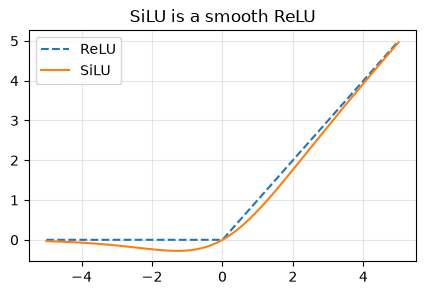

In [19]:
def silu(x):
    return x * torch.sigmoid(x)


xs = torch.linspace(-5, 5, 200)
plt.figure(figsize=(5, 3))
plt.plot(xs, torch.relu(xs), label="ReLU", ls="--")
plt.plot(xs, silu(xs), label="SiLU")
plt.legend(); plt.grid(alpha=0.3); plt.title("SiLU is a smooth ReLU"); plt.show()

In [20]:
def default_d_ff(d_model):
    return int(64 * math.ceil((8 * d_model / 3) / 64))


class SwiGLU(nn.Module):
    def __init__(self, d_model, d_ff=None, device=None, dtype=None):
        super().__init__()
        d_ff = d_ff or default_d_ff(d_model)
        self.w1 = Linear(d_model, d_ff, device=device, dtype=dtype)
        self.w2 = Linear(d_ff, d_model, device=device, dtype=dtype)
        self.w3 = Linear(d_model, d_ff, device=device, dtype=dtype)

    def forward(self, x):
        return self.w2(silu(self.w1(x)) * self.w3(x))


ffn = SwiGLU(d_model=128)
print("d_ff for d_model=128:", default_d_ff(128))
print("output shape:", ffn(torch.randn(2, 10, 128)).shape)

d_ff for d_model=128: 384
output shape: torch.Size([2, 10, 128])


## 2.5 Softmax (the numerically stable way)

Softmax turns a vector of scores into probabilities: $\text{softmax}(x)_i = \dfrac{e^{x_i}}{\sum_j e^{x_j}}$.

The naive formula breaks for large scores, because $e^{1000}$ overflows to infinity. The fix: subtracting the same number from every score doesn't change the result, so we **subtract the maximum first**. That way the largest exponent is $e^0 = 1$.

In [21]:
scores = torch.tensor([1000.0, 1001.0, 1002.0])
naive = torch.exp(scores) / torch.exp(scores).sum()
print("naive: ", naive, " <- inf / inf = nan 💥")


def softmax(x, dim=-1):
    x = x - x.max(dim=dim, keepdim=True).values
    e = torch.exp(x)
    return e / e.sum(dim=dim, keepdim=True)


print("stable:", softmax(scores))

# ✅ Check against PyTorch
x = torch.randn(4, 10)
assert torch.allclose(softmax(x, dim=-1), torch.softmax(x, dim=-1), atol=1e-6)
print("✅ matches torch.softmax")

naive:  tensor([nan, nan, nan])  <- inf / inf = nan 💥
stable: tensor([0.0900, 0.2447, 0.6652])
✅ matches torch.softmax


## 2.6 Where is each token? Rotary position embeddings (RoPE)

Attention works by comparing tokens with dot products: *"how relevant is token $n$ to token $m$?"*. But a dot product has **no idea where the tokens are**. Without extra help, *"the dog bit the man"* and *"the man bit the dog"* would look the same to attention. We need to inject position information.

* GPT-2 learned a separate "position vector" for each position and added it to the embeddings.
* Modern models (LLaMA, Mistral, Qwen, ...) use **RoPE**: they **rotate** the query and key vectors by an angle proportional to their position.

### The idea in 2D

Take a 2D query vector $q$ for a token at position $m$, and rotate it by angle $m\theta$. Take a key vector $k$ for a token at position $n$, and rotate it by $n\theta$. The dot product of two vectors depends only on their lengths and the **angle between them**. So after rotating, the score depends on $(m - n)\theta$, which is the **relative distance** between the tokens. Moving both tokens along by the same amount doesn't change the score:

In [22]:
def rotate_2d(v, angle):
    c, s = math.cos(angle), math.sin(angle)
    return torch.tensor([c * v[0] - s * v[1],
                         s * v[0] + c * v[1]])


q, k, theta = torch.tensor([1.0, 0.5]), torch.tensor([0.3, 2.0]), 0.4
for m, n in [(1, 0), (5, 4), (50, 49), (3, 0), (8, 5)]:
    score = rotate_2d(q, m * theta) @ rotate_2d(k, n * theta)
    print(f"query at position {m:2d}, key at position {n:2d}  (distance {m - n}):  score = {score:+.4f}")

query at position  1, key at position  0  (distance 1):  score = +1.9178
query at position  5, key at position  4  (distance 1):  score = +1.9178
query at position 50, key at position 49  (distance 1):  score = +1.9178
query at position  3, key at position  0  (distance 3):  score = +2.1953
query at position  8, key at position  5  (distance 3):  score = +2.1953


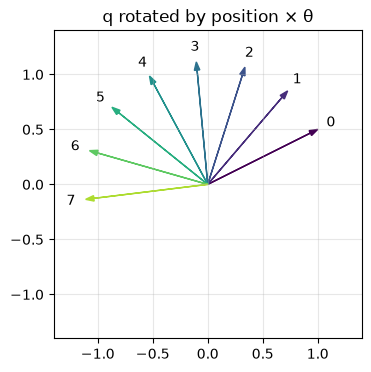

In [23]:
# The same query vector, rotated for positions 0..7
plt.figure(figsize=(4, 4))
for m in range(8):
    v = rotate_2d(q, m * theta)
    plt.arrow(0, 0, v[0].item(), v[1].item(), head_width=0.05, color=plt.cm.viridis(m / 8), length_includes_head=True)
    plt.text(v[0].item() * 1.12, v[1].item() * 1.12, str(m), ha="center", va="center")
plt.xlim(-1.4, 1.4); plt.ylim(-1.4, 1.4); plt.gca().set_aspect("equal"); plt.grid(alpha=0.3)
plt.title("q rotated by position × θ"); plt.show()

### From 2D to d dimensions

Our query and key vectors have $d_k$ dimensions (e.g. 32), not 2. RoPE splits them into $d_k/2$ **pairs** of neighbouring entries, $(x_0, x_1), (x_2, x_3), \dots$, and rotates each pair as a little 2D vector.

Each pair $i$ gets its **own speed** $\theta_i$:

$$\theta_i = \Theta^{-2i/d_k}, \qquad i = 0, 1, \dots, \tfrac{d_k}{2} - 1, \qquad \Theta = 10000$$

The first pair rotates fast (1 radian per position), while the last pairs rotate *very* slowly. Think of the hands of a clock: fast hands tell nearby positions apart, slow hands keep track of long distances.

For a token at position $m$, pair $i$ is rotated like this:

$$\begin{pmatrix} x'_{2i} \\ x'_{2i+1} \end{pmatrix} = \begin{pmatrix} \cos(m\theta_i) & -\sin(m\theta_i) \\ \sin(m\theta_i) & \cos(m\theta_i) \end{pmatrix} \begin{pmatrix} x_{2i} \\ x_{2i+1} \end{pmatrix}$$

i.e. $\;x'_{2i} = x_{2i}\cos(m\theta_i) - x_{2i+1}\sin(m\theta_i)\;$ and $\;x'_{2i+1} = x_{2i}\sin(m\theta_i) + x_{2i+1}\cos(m\theta_i)$.

RoPE has **no learnable parameters**. It's applied to the queries and keys inside attention (not the values), separately in each attention head.

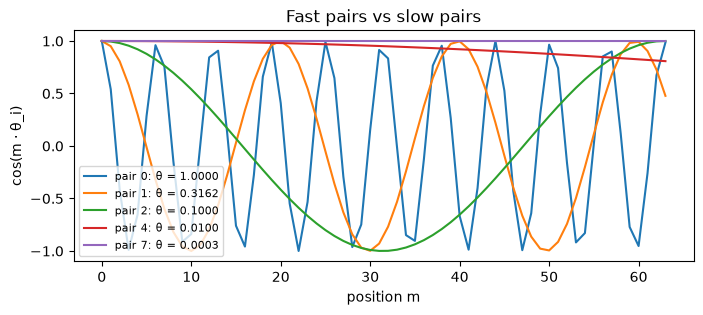

In [24]:
# Each pair rotates at its own speed (here d_k = 16, so there are 8 pairs)
d_k, positions = 16, torch.arange(64)
plt.figure(figsize=(8, 3))
for i in [0, 1, 2, 4, 7]:
    theta_i = 10000 ** (-2 * i / d_k)
    plt.plot(positions, torch.cos(positions * theta_i), label=f"pair {i}: θ = {theta_i:.4f}")
plt.xlabel("position m"); plt.ylabel("cos(m · θ_i)"); plt.legend(fontsize=8, loc="lower left")
plt.title("Fast pairs vs slow pairs"); plt.show()

---
# Homework: implement RoPE

Fill in the class below. Use the 2D demo and the formulas above as your guide.

**What it should do:**
* `__init__(theta, d_k, max_seq_len, device=None)`: precompute $\cos(m\theta_i)$ and $\sin(m\theta_i)$ for every position $m < $ `max_seq_len` and every pair $i$. Store them with `self.register_buffer(..., persistent=False)`. A buffer is a tensor that belongs to the module (it moves with `.to(device)`) but **isn't trained**.
* `forward(x, token_positions)`: `x` has shape `(..., seq_len, d_k)` and `token_positions` has shape `(..., seq_len)`. Return the rotated tensor, with the same shape as `x`.

**Convention:** the pairs are *neighbouring* entries, $(x_0, x_1), (x_2, x_3), \dots$. The tests depend on this.

**Useful PyTorch tools:**
* `torch.arange(n)` gives `[0, 1, ..., n-1]`.
* `a[:, None] * b[None, :]` is an "outer product" that makes a table of all combinations.
* `x[..., 0::2]` and `x[..., 1::2]` select the even and odd entries of the last dimension.
* Indexing a table with a tensor of positions, `table[token_positions]`, picks out the right rows.
* `torch.stack([a, b], dim=-1).flatten(-2)` interleaves `[a0, a1, ...]` and `[b0, b1, ...]` into `[a0, b0, a1, b1, ...]`.

**Run the test cell when you're done.** It checks shapes, a hand-computable example, and the relative-position property from the 2D demo.

Theres a great blog post by Jane street showing how RoPE is the best method for positional embedding: https://blog.janestreet.com/using-group-theory-to-explore-positional-encodings-attention/ 

In [25]:
class RotaryPositionalEmbedding(nn.Module):
    """
    Rotary position embedding (RoPE).

    Args:
        theta:       the base Θ (10000 in most models)
        d_k:         size of the vectors to rotate (the attention head dimension); must be even
        max_seq_len: the longest sequence we will ever see (so the angles can be precomputed)
    """

    def __init__(self, theta, d_k, max_seq_len, device=None):
        super().__init__()
        assert d_k % 2 == 0, "d_k must be even"
        # ===================== YOUR CODE HERE =====================
        # Step 1: the d_k/2 frequencies   theta_i = theta ** (-2 * i / d_k)    for i = 0, 1, ..., d_k/2 - 1
        # Step 2: the positions           m = 0, 1, ..., max_seq_len - 1
        # Step 3: the angles              angle[m, i] = m * theta_i            -> shape (max_seq_len, d_k // 2)
        # Step 4: store the cos and sin of the angles as buffers:
        #             self.register_buffer("cos", ..., persistent=False)
        #             self.register_buffer("sin", ..., persistent=False)
        raise NotImplementedError("Homework: implement RotaryPositionalEmbedding.__init__")
        # ==========================================================

    def forward(self, x, token_positions):
        """
        x:               (..., seq_len, d_k)
        token_positions: (..., seq_len)  integer position of each token
        returns:         a tensor with the same shape as x
        """
        # ===================== YOUR CODE HERE =====================
        # Step 1: look up the cos and sin for each token's position   -> shape (..., seq_len, d_k // 2)
        # Step 2: split x into its even entries x[..., 0::2] and odd entries x[..., 1::2]
        # Step 3: rotate each (even, odd) pair with the 2D rotation formula
        # Step 4: interleave the results back into shape (..., seq_len, d_k)
        # Don't modify x in place (e.g. x[..., 0::2] = ...): that breaks autograd. Build a new tensor.
        raise NotImplementedError("Homework: implement RotaryPositionalEmbedding.forward")
        # ==========================================================

In [26]:
def test_rope(RoPEClass, verbose=True):
    """Run a set of checks on a RoPE implementation. Returns True if all of them pass."""

    def same_shape():
        rope = RoPEClass(10000.0, 16, 32, device="cpu")
        x = torch.randn(2, 3, 10, 16)                       # (batch, heads, seq, d_k)
        return rope(x, torch.arange(10)).shape == x.shape

    def no_trainable_parameters():
        return len(list(RoPEClass(10000.0, 16, 32).parameters())) == 0

    def position_zero_is_identity():
        x = torch.randn(1, 16)
        return torch.allclose(RoPEClass(10000.0, 16, 32)(x, torch.tensor([0])), x, atol=1e-6)

    def preserves_vector_length():
        x = torch.randn(10, 16)
        out = RoPEClass(10000.0, 16, 32)(x, torch.arange(10))
        return torch.allclose(out.norm(dim=-1), x.norm(dim=-1), atol=1e-5)

    def matches_hand_computed_example():
        # d_k = 4 -> two pairs: (1, 2) rotates by 1 radian, (3, 4) by 0.01 radians. Check it on paper!
        out = RoPEClass(10000.0, 4, 8)(torch.tensor([[1.0, 2.0, 3.0, 4.0]]), torch.tensor([1]))
        expected = torch.tensor([[-1.142640, 1.922076, 2.959851, 4.029800]])
        return torch.allclose(out, expected, atol=1e-5)

    def score_depends_only_on_distance():
        rope = RoPEClass(10000.0, 16, 64)
        q, k = torch.randn(1, 16), torch.randn(1, 16)
        def score(m, n):
            return (rope(q, torch.tensor([m])) * rope(k, torch.tensor([n]))).sum().item()
        scores = [score(5, 3), score(12, 10), score(40, 38)]
        return max(scores) - min(scores) < 1e-4

    def any_positions_and_batch_dims():
        rope = RoPEClass(10000.0, 8, 16)
        x = torch.randn(2, 3, 8)
        pos = torch.tensor([[7, 0, 3], [1, 2, 15]])         # different positions for each batch element
        out = rope(x, pos)
        return all(torch.allclose(out[b, j], rope(x[b, j:j + 1], pos[b, j:j + 1])[0], atol=1e-6)
                   for b in range(2) for j in range(3))

    def does_not_modify_input():
        x = torch.randn(4, 8)
        x_before = x.clone()
        RoPEClass(10000.0, 8, 16)(x, torch.arange(4))
        return torch.equal(x, x_before)

    def gradients_flow():
        x = torch.randn(4, 8, requires_grad=True)
        RoPEClass(10000.0, 8, 16)(x, torch.arange(4)).pow(2).sum().backward()
        # rotations preserve length, so d/dx of sum(out^2) = d/dx of sum(x^2) = 2x
        return x.grad is not None and torch.allclose(x.grad, 2 * x.detach(), atol=1e-5)

    checks = [same_shape, no_trainable_parameters, position_zero_is_identity, preserves_vector_length,
              matches_hand_computed_example, score_depends_only_on_distance, any_positions_and_batch_dims,
              does_not_modify_input, gradients_flow]
    torch.manual_seed(0)
    results, lines, not_implemented = [], [], 0
    for check in checks:
        try:
            ok, note = bool(check()), ""
        except NotImplementedError:
            ok, note = False, "  (not implemented yet)"
            not_implemented += 1
        except Exception as e:
            ok, note = False, f"  ({type(e).__name__}: {e})"
        results.append(ok)
        lines.append(f"{'✅' if ok else '❌'} {check.__name__.replace('_', ' ')}{note}")

    if verbose:
        if not_implemented == len(checks):
            print("⏳ RoPE isn't implemented yet. That's your homework!")
        else:
            print("\n".join(lines))
            if all(results):
                print(f"\n🎉 All {len(checks)} checks passed!")
            else:
                print(f"\n{sum(results)}/{len(checks)} checks passed. Keep going!")
    return all(results)


test_rope(RotaryPositionalEmbedding)

⏳ RoPE isn't implemented yet. That's your homework!


False

### Bonus questions to think about

1. Why do we rotate the queries and keys, but **not** the values?
2. The first pair rotates by 1 radian per position, so it "wraps around" every ~6 positions. The last pair barely moves. Why might a model want *both*?
3. GPT-2 *added* a learned position vector to each token embedding. What can RoPE do that GPT-2's approach can't? (Hint: think about relative distances.)

---
## End of session 1

You've built a complete BPE tokenizer and encoded the dataset. You've also built the Linear, Embedding, RMSNorm, SwiGLU and softmax layers, which are most of the parts of a Transformer. Your tokenizer and token ids are saved in `data/`.

**Next session:** attention, the full model, and training it.

---
---
# Session 2: attention, the full model, and training

### Before you start

1. **Restart the kernel.** In the menu: *Kernel → Restart*.
2. **Run every cell above this one.**
   * JupyterLab: *Run → Run All Above Selected Cell*.
   * Classic Notebook: *Cell → Run All Above*.
   * VS Code: click *Execute Above Cells* on this cell.

   The tokenizer and dataset are cached, so this only takes a few seconds.
3. Put **`rope_solution.py`**  in the same folder as this notebook.

The cell below decides which RoPE to use for the rest of the notebook. If your homework passes all the tests, we use **yours**. If not, we fall back to the reference solution, so you can keep going and fix yours later.

In [27]:
if test_rope(RotaryPositionalEmbedding, verbose=False):
    RoPE = RotaryPositionalEmbedding
    print("✅ Using your RoPE implementation. Good Job!")
else:
    try:
        from rope_solution import RotaryPositionalEmbedding as RoPE
    except ImportError:
        raise RuntimeError("Your RoPE doesn't pass the tests yet, and rope_solution.py wasn't found next to this "
                           "notebook.")
    assert test_rope(RoPE, verbose=False)
    print("Your RoPE doesn't pass the tests yet, so we'll use the reference solution from rope_solution.py.")

Your RoPE doesn't pass the tests yet, so we'll use the reference solution from rope_solution.py.


---
# Part 3 — Attention

Attention is how tokens share information. Every token produces three vectors:

* a **query** $q$: *"what am I looking for?"*
* a **key** $k$: *"what do I contain?"*
* a **value** $v$: *"what will I pass on if you pick me?"*

Each token compares its query with every key (dot products), turns the scores into weights with softmax, and takes a **weighted average of the values**.

## 3.1 Scaled dot-product attention

With all queries, keys and values stacked into matrices:

$$\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{Q K^\top}{\sqrt{d_k}}\right) V$$

**Why divide by $\sqrt{d_k}$?** A dot product of two random $d_k$-dimensional vectors has a standard deviation of about $\sqrt{d_k}$. Large scores make softmax almost one-hot, which means tiny gradients and slow learning. Dividing by $\sqrt{d_k}$ brings the scores back to a standard deviation of about 1:

In [28]:
for d in [4, 64, 1024]:
    q, k = torch.randn(10_000, d), torch.randn(10_000, d)
    dots = (q * k).sum(-1)
    print(f"d_k = {d:4d}:  std of q·k = {dots.std():6.2f}   std of q·k / sqrt(d_k) = {(dots / math.sqrt(d)).std():.2f}")

d_k =    4:  std of q·k =   2.00   std of q·k / sqrt(d_k) = 1.00
d_k =   64:  std of q·k =   8.01   std of q·k / sqrt(d_k) = 1.00
d_k = 1024:  std of q·k =  32.09   std of q·k / sqrt(d_k) = 1.00


### The causal mask: no peeking at the future

A language model predicts the *next* token, so position $m$ may only look at positions $\le m$. Otherwise it could just copy the answer! We enforce this with a **causal mask**: a lower-triangular matrix of allowed (`True`) and blocked (`False`) positions. Blocked scores are set to $-\infty$ *before* the softmax, so they get weight exactly 0.

In [29]:
print(torch.tril(torch.ones(5, 5, dtype=torch.bool)).int())
print("row = query position, column = key position, 1 = allowed to look")

tensor([[1, 0, 0, 0, 0],
        [1, 1, 0, 0, 0],
        [1, 1, 1, 0, 0],
        [1, 1, 1, 1, 0],
        [1, 1, 1, 1, 1]], dtype=torch.int32)
row = query position, column = key position, 1 = allowed to look


In [30]:
def scaled_dot_product_attention(Q, K, V, mask=None):
    """
    Q: (..., n_queries, d_k)   K: (..., n_keys, d_k)   V: (..., n_keys, d_v)
    mask: (n_queries, n_keys) booleans, True = allowed to attend
    returns: (..., n_queries, d_v)
    """
    d_k = Q.shape[-1]
    scores = Q @ K.transpose(-2, -1) / math.sqrt(d_k)          # (..., n_queries, n_keys)
    if mask is not None:
        scores = scores.masked_fill(~mask, float("-inf"))      # blocked positions get -inf
    weights = softmax(scores, dim=-1)                          # each row sums to 1
    return weights @ V


# ✅ Check against PyTorch's built-in version
Q, K, V = torch.randn(2, 6, 8), torch.randn(2, 6, 8), torch.randn(2, 6, 8)
causal = torch.tril(torch.ones(6, 6, dtype=torch.bool))
ours = scaled_dot_product_attention(Q, K, V, causal)
ref = torch.nn.functional.scaled_dot_product_attention(Q, K, V, is_causal=True)
assert torch.allclose(ours, ref, atol=1e-5)
print("✅ matches torch.nn.functional.scaled_dot_product_attention")

✅ matches torch.nn.functional.scaled_dot_product_attention


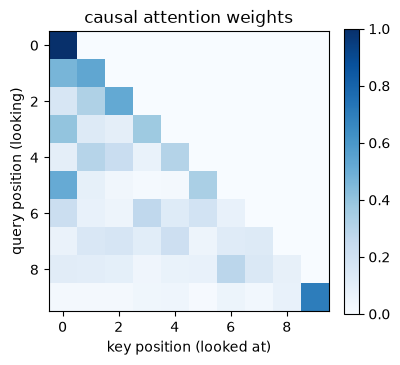

In [31]:
# What do the attention weights look like? (random Q and K, so the pattern is random, but note the triangle)
T = 10
scores = torch.randn(T, 8) @ torch.randn(T, 8).T / math.sqrt(8)
weights = softmax(scores.masked_fill(~torch.tril(torch.ones(T, T, dtype=torch.bool)), float("-inf")))
plt.figure(figsize=(4, 4))
plt.imshow(weights, cmap="Blues")
plt.xlabel("key position (looked at)"); plt.ylabel("query position (looking)")
plt.title("causal attention weights"); plt.colorbar(fraction=0.046); plt.show()

## 3.2 Multi-head self-attention

One attention pattern can only focus on one kind of relationship at a time. **Multi-head attention** runs several attentions in parallel ("heads"), each on a slice of size $d_\text{head} = d_\text{model} / \text{num\_heads}$. One head might track the subject of the sentence, while another looks at the previous word.

Step by step, for an input `x` of shape `(batch, seq, d_model)`:

1. Project the input to queries, keys and values: three `Linear(d_model, d_model)` layers.
2. **Split into heads:** reshape `(batch, seq, d_model)` → `(batch, heads, seq, d_head)`.
3. **Apply RoPE** to the queries and keys. ← *your homework is used here!*
4. Run causal scaled dot-product attention in every head at once (the `heads` dimension acts like a batch dimension).
5. **Merge the heads:** `(batch, heads, seq, d_head)` → `(batch, seq, d_model)`.
6. Apply a final output projection, `Linear(d_model, d_model)`.

In [32]:
class MultiHeadSelfAttention(nn.Module):
    def __init__(self, d_model, num_heads, max_seq_len, rope_theta=10000.0, device=None, dtype=None):
        super().__init__()
        assert d_model % num_heads == 0, "d_model must be divisible by num_heads"
        self.num_heads = num_heads
        self.d_head = d_model // num_heads
        self.q_proj = Linear(d_model, d_model, device=device, dtype=dtype)
        self.k_proj = Linear(d_model, d_model, device=device, dtype=dtype)
        self.v_proj = Linear(d_model, d_model, device=device, dtype=dtype)
        self.output_proj = Linear(d_model, d_model, device=device, dtype=dtype)
        self.rope = RoPE(rope_theta, self.d_head, max_seq_len, device=device)
        mask = torch.tril(torch.ones(max_seq_len, max_seq_len, dtype=torch.bool, device=device))
        self.register_buffer("causal_mask", mask, persistent=False)

    def forward(self, x, token_positions=None):
        batch, seq, d_model = x.shape
        if token_positions is None:
            token_positions = torch.arange(seq, device=x.device)

        def split_heads(t):   # (batch, seq, d_model) -> (batch, heads, seq, d_head)
            return t.view(batch, seq, self.num_heads, self.d_head).transpose(1, 2)

        q = split_heads(self.q_proj(x))
        k = split_heads(self.k_proj(x))
        v = split_heads(self.v_proj(x))

        q = self.rope(q, token_positions)
        k = self.rope(k, token_positions)

        out = scaled_dot_product_attention(q, k, v, self.causal_mask[:seq, :seq])   # (batch, heads, seq, d_head)
        out = out.transpose(1, 2).reshape(batch, seq, d_model)                       # merge the heads
        return self.output_proj(out)

In [33]:
# ✅ Check: shapes, and that no position can see the future
mha = MultiHeadSelfAttention(d_model=32, num_heads=4, max_seq_len=16)
x = torch.randn(1, 10, 32)
out1 = mha(x)
print("output shape:", out1.shape)

x2 = x.clone()
x2[:, 6] = torch.randn(32)     # change token 6 only
out2 = mha(x2)
print("outputs at positions 0-5 unchanged:", torch.allclose(out1[:, :6], out2[:, :6]))
print("outputs at positions 6-9 changed:  ", not torch.allclose(out1[:, 6:], out2[:, 6:]))

output shape: torch.Size([1, 10, 32])
outputs at positions 0-5 unchanged: True
outputs at positions 6-9 changed:   True


---
# Part 4 — The full Transformer language model

## 4.1 The Transformer block

Each block has two sub-layers, and each one is wrapped the same way:

$$x \leftarrow x + \text{SubLayer}(\text{RMSNorm}(x))$$

The `x + ...` is a **residual connection**. Every block only *adds* a small update to the vector, which keeps a clean path for information (and gradients) to flow through many layers. Normalizing *before* each sub-layer ("pre-norm") makes deep models much easier to train than the original Transformer's "post-norm".

In [34]:
class TransformerBlock(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, max_seq_len, rope_theta=10000.0, device=None, dtype=None):
        super().__init__()
        self.ln1 = RMSNorm(d_model, device=device, dtype=dtype)
        self.attn = MultiHeadSelfAttention(d_model, num_heads, max_seq_len, rope_theta, device=device, dtype=dtype)
        self.ln2 = RMSNorm(d_model, device=device, dtype=dtype)
        self.ffn = SwiGLU(d_model, d_ff, device=device, dtype=dtype)

    def forward(self, x):
        x = x + self.attn(self.ln1(x))    # tokens exchange information
        x = x + self.ffn(self.ln2(x))     # each token processes what it gathered
        return x

## 4.2 The language model

Now we stack everything: embedding → blocks → final norm → output layer ("LM head").

The model's size is set by a few numbers. The ones below are tiny on purpose, so the model trains on a laptop.

In [35]:
@dataclass
class ModelConfig:
    vocab_size: int = VOCAB_SIZE
    context_length: int = 128     # the longest sequence the model sees at once
    d_model: int = 128            # size of each token's vector
    num_layers: int = 4           # number of Transformer blocks
    num_heads: int = 4            # attention heads per block (d_head = 128 / 4 = 32)
    d_ff: int = 384               # hidden size of the feed-forward network (≈ 8/3 × d_model)
    rope_theta: float = 10000.0


class TransformerLM(nn.Module):
    def __init__(self, config, device=None, dtype=None):
        super().__init__()
        self.config = config
        self.token_embeddings = Embedding(config.vocab_size, config.d_model, device=device, dtype=dtype)
        self.layers = nn.ModuleList([
            TransformerBlock(config.d_model, config.num_heads, config.d_ff, config.context_length,
                             config.rope_theta, device=device, dtype=dtype)
            for _ in range(config.num_layers)
        ])
        self.ln_final = RMSNorm(config.d_model, device=device, dtype=dtype)
        self.lm_head = Linear(config.d_model, config.vocab_size, device=device, dtype=dtype)

    def forward(self, token_ids):
        # token_ids: (batch, seq)  ->  logits: (batch, seq, vocab_size)
        x = self.token_embeddings(token_ids)
        for layer in self.layers:
            x = layer(x)
        return self.lm_head(self.ln_final(x))


model_cfg = ModelConfig(vocab_size=tokenizer.vocab_size)
model = TransformerLM(model_cfg, device=DEVICE)

dummy = torch.randint(0, model_cfg.vocab_size, (2, 16), device=DEVICE)
print("input shape: ", dummy.shape)
print("logits shape:", model(dummy).shape, " <- a score for every vocab token, at every position")

input shape:  torch.Size([2, 16])
logits shape: torch.Size([2, 16, 2048])  <- a score for every vocab token, at every position


### Where do the parameters live?

In [36]:
def count_params(module):
    return sum(p.numel() for p in module.parameters())


total = count_params(model)
for name, part in [("token embeddings", model.token_embeddings),
                   (f"{model_cfg.num_layers} transformer blocks", model.layers),
                   ("   ↳ attention (per block)", model.layers[0].attn),
                   ("   ↳ feed-forward (per block)", model.layers[0].ffn),
                   ("final RMSNorm", model.ln_final),
                   ("output layer (lm_head)", model.lm_head)]:
    n = count_params(part)
    print(f"{name:32s} {n:>10,}  ({100 * n / total:4.1f}%)")
print(f"{'TOTAL':32s} {total:>10,}")
print(f"\nFor comparison: GPT-2 small has 124M parameters and LLaMA-3 8B has 8,000M.")

token embeddings                    262,144  (19.0%)
4 transformer blocks                852,992  (61.9%)
   ↳ attention (per block)           65,536  ( 4.8%)
   ↳ feed-forward (per block)       147,456  (10.7%)
final RMSNorm                           128  ( 0.0%)
output layer (lm_head)              262,144  (19.0%)
TOTAL                             1,377,408

For comparison: GPT-2 small has 124M parameters and LLaMA-3 8B has 8,000M.


In such a small model, a big share of the parameters sits in the embedding and output layers, because `vocab_size` is large compared to `d_model`. In big models, the Transformer blocks dominate.

---
# Part 5 — Training ingredients

Training repeats the same loop thousands of times:

```
grab a batch of text  →  model predicts the next token everywhere  →  measure how wrong (loss)
        ↑                                                                        ↓
        └──────────────  nudge every parameter to be a bit less wrong  ←  compute gradients
```

We need: a **loss**, an **optimizer**, a **learning-rate schedule**, **gradient clipping** and a **data loader**.

## 5.1 Cross-entropy loss

At each position, the model outputs logits $o$ (one score per vocab token). Softmax turns them into probabilities, and the loss is the **negative log-probability of the correct next token**:

$$\ell = -\log \text{softmax}(o)_{\text{target}} = \log \sum_j e^{o_j} \;-\; o_{\text{target}}$$

We average this over every position in the batch. As with softmax, we subtract the max first for numerical stability.

**A sanity check:** an untrained model guesses roughly uniformly over $V$ tokens, so its loss should be close to $\log V = \log 2048 \approx 7.62$. The **perplexity** $e^{\text{loss}}$ is the "effective number of tokens the model is choosing between".

In [37]:
def cross_entropy(logits, targets):
    """logits: (..., vocab_size), targets: (...) integer ids. Returns the mean loss (a scalar)."""
    logits = logits.reshape(-1, logits.shape[-1]).float()      # (N, vocab)
    targets = targets.reshape(-1)                              # (N,)
    logits = logits - logits.max(dim=-1, keepdim=True).values  # for numerical stability
    log_sum_exp = torch.log(torch.exp(logits).sum(dim=-1))     # (N,)
    correct = logits[torch.arange(len(targets)), targets]      # score of the right answer, (N,)
    return (log_sum_exp - correct).mean()


# ✅ Check against PyTorch
logits, targets = torch.randn(4, 7, 50), torch.randint(0, 50, (4, 7))
assert torch.allclose(cross_entropy(logits, targets), torch.nn.functional.cross_entropy(logits.view(-1, 50), targets.view(-1)))
print("✅ matches torch.nn.functional.cross_entropy")

# Sanity check on our untrained model
x = torch.randint(0, model_cfg.vocab_size, (4, 32), device=DEVICE)
with torch.no_grad():
    loss = cross_entropy(model(x[:, :-1]), x[:, 1:])
print(f"untrained loss: {loss:.2f}   vs   log(vocab_size) = {math.log(model_cfg.vocab_size):.2f}")

✅ matches torch.nn.functional.cross_entropy
untrained loss: 7.61   vs   log(vocab_size) = 7.62


## 5.2 The AdamW optimizer

Plain gradient descent updates every parameter as $\theta \leftarrow \theta - \alpha \nabla\ell$. **AdamW** improves on this in three ways:

* **Momentum** $m$: a running average of the gradients, which smooths out noisy batches.
* **Per-parameter step sizes** $v$: a running average of the *squared* gradients. Parameters with consistently large gradients take smaller steps, and vice versa.
* **Weight decay** $\lambda$: every step, it shrinks all the weights slightly towards zero, which is a simple form of regularization. The "W" in AdamW means this is done separately from the gradient step ("decoupled").

For each parameter, at step $t$ (starting at 1):

$$m \leftarrow \beta_1 m + (1-\beta_1)\, g \qquad v \leftarrow \beta_2 v + (1-\beta_2)\, g^2 \qquad \alpha_t = \alpha\, \frac{\sqrt{1-\beta_2^t}}{1-\beta_1^t}$$
$$\theta \leftarrow \theta - \alpha_t \frac{m}{\sqrt{v} + \epsilon} \qquad\qquad \theta \leftarrow \theta - \alpha\lambda\theta$$

(The $\alpha_t$ factor corrects for $m$ and $v$ starting at zero.)

PyTorch optimizers keep their settings in `self.param_groups` and any per-parameter memory (here $m$, $v$ and $t$) in `self.state`.

In [38]:
class AdamW(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.01):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None if closure is None else closure()
        for group in self.param_groups:
            lr, (beta1, beta2), eps, wd = group["lr"], group["betas"], group["eps"], group["weight_decay"]
            for p in group["params"]:
                if p.grad is None:
                    continue
                g = p.grad
                state = self.state[p]
                if len(state) == 0:                          # first step for this parameter
                    state["t"] = 0
                    state["m"] = torch.zeros_like(p)
                    state["v"] = torch.zeros_like(p)
                state["t"] += 1
                t, m, v = state["t"], state["m"], state["v"]

                m.mul_(beta1).add_(g, alpha=1 - beta1)          # m = β1·m + (1-β1)·g
                v.mul_(beta2).addcmul_(g, g, value=1 - beta2)   # v = β2·v + (1-β2)·g²
                alpha_t = lr * math.sqrt(1 - beta2 ** t) / (1 - beta1 ** t)

                # PyTorch applies the weight decay just before the Adam step. The order barely
                # matters, but matching PyTorch lets us check our implementation against it.
                p.mul_(1 - lr * wd)                             # θ = θ - α·λ·θ
                p.addcdiv_(m, v.sqrt().add_(eps), value=-alpha_t)  # θ = θ - α_t · m / (√v + ε)
        return loss

In [39]:
# ✅ Check: our AdamW and PyTorch's take exactly the same steps on a small problem
torch.manual_seed(0)
target = torch.randn(5, 3)
w_ours = nn.Parameter(torch.randn(5, 3))
w_ref = nn.Parameter(w_ours.detach().clone())
opt_ours = AdamW([w_ours], lr=0.1, betas=(0.9, 0.95), weight_decay=0.1)
opt_ref = torch.optim.AdamW([w_ref], lr=0.1, betas=(0.9, 0.95), weight_decay=0.1)
for _ in range(50):
    for w, opt in [(w_ours, opt_ours), (w_ref, opt_ref)]:
        opt.zero_grad()
        ((w - target) ** 2).sum().backward()
        opt.step()
assert torch.allclose(w_ours, w_ref, atol=1e-5)
print("✅ matches torch.optim.AdamW")

✅ matches torch.optim.AdamW


## 5.3 Learning-rate schedule: warmup + cosine decay

Big steps help early in training, and small steps help fine-tune at the end. The standard recipe:

* **Warmup:** increase the learning rate linearly from 0 to `max_lr`. At the very start the gradients are large and chaotic, so we start gently.
* **Cosine decay:** then smoothly lower it to `min_lr`, following half a cosine wave.

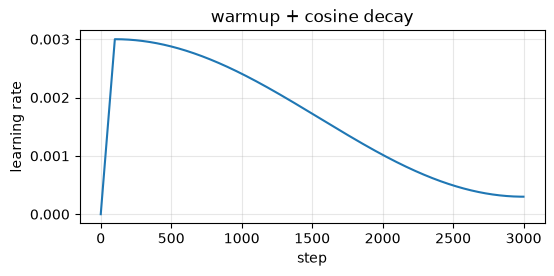

In [40]:
def lr_cosine_schedule(t, max_lr, min_lr, warmup_steps, total_steps):
    if t < warmup_steps:
        return max_lr * t / warmup_steps
    if t > total_steps:
        return min_lr
    progress = (t - warmup_steps) / max(1, total_steps - warmup_steps)   # goes from 0 to 1
    return min_lr + 0.5 * (1 + math.cos(math.pi * progress)) * (max_lr - min_lr)


steps = range(3000)
plt.figure(figsize=(6, 2.5))
plt.plot(steps, [lr_cosine_schedule(t, 3e-3, 3e-4, 100, 3000) for t in steps])
plt.xlabel("step"); plt.ylabel("learning rate"); plt.title("warmup + cosine decay"); plt.grid(alpha=0.3); plt.show()

## 5.4 Gradient clipping

Every now and then, an unlucky batch produces a huge gradient that would knock the model far off course. **Gradient clipping** is a safety net. We compute the total size (L2 norm) of *all* the gradients together, and if it's larger than `max_norm`, we scale them all down so the norm equals `max_norm`. The direction stays the same; only the step size is capped.

In [41]:
def clip_gradients(parameters, max_norm, eps=1e-6):
    grads = [p.grad for p in parameters if p.grad is not None]
    total_norm = torch.sqrt(sum((g.float() ** 2).sum() for g in grads))
    if total_norm > max_norm:
        scale = max_norm / (total_norm + eps)
        for g in grads:
            g.mul_(scale)
    return total_norm


# ✅ Check against PyTorch
a, b = nn.Parameter(torch.randn(10)), nn.Parameter(torch.randn(10))
a.grad, b.grad = torch.randn(10) * 5, torch.randn(10) * 5
ga, gb = a.grad.clone(), b.grad.clone()
clip_gradients([a, b], max_norm=1.0)
a.grad, b.grad = ga, gb
torch.nn.utils.clip_grad_norm_([a, b], max_norm=1.0)
assert torch.allclose(torch.cat([ga, gb]), torch.cat([a.grad, b.grad]), atol=1e-5)
print("✅ matches torch.nn.utils.clip_grad_norm_")

✅ matches torch.nn.utils.clip_grad_norm_


## 5.5 Data loading

Our training data is one long array of token ids. To make a batch, we pick `batch_size` random starting points and cut out `context_length` tokens from each. The **targets are the same tokens shifted by one**. At every position, the model's job is to predict the next token.

So a single sequence of length `context_length` gives us `context_length` training examples at once!

In [42]:
def get_batch(data, batch_size, context_length, device="cpu", rng=np.random):
    starts = rng.randint(0, len(data) - context_length, size=batch_size)
    x = np.stack([data[s : s + context_length] for s in starts]).astype(np.int64)
    y = np.stack([data[s + 1 : s + 1 + context_length] for s in starts]).astype(np.int64)
    return torch.from_numpy(x).to(device), torch.from_numpy(y).to(device)


x, y = get_batch(train_ids, batch_size=4, context_length=8)
print("x shape:", x.shape, "  y shape:", y.shape, "\n")
print("The 8 training examples hidden in the first row:")
for t in range(8):
    context = tokenizer.decode(x[0, : t + 1].tolist())
    print(f"  given {context!r:55} -> predict {tokenizer.decode([y[0, t].item()])!r}")

x shape: torch.Size([4, 8])   y shape: torch.Size([4, 8]) 

The 8 training examples hidden in the first row:
  given "'s"                                                    -> predict ' toys'
  given "'s toys"                                               -> predict ' to'
  given "'s toys to"                                            -> predict ' him'
  given "'s toys to him"                                        -> predict '.'
  given "'s toys to him."                                       -> predict ' He'
  given "'s toys to him. He"                                    -> predict ' would'
  given "'s toys to him. He would"                              -> predict ' carry'
  given "'s toys to him. He would carry"                        -> predict ' them'


(For datasets too big to fit in memory, you'd use `np.load(path, mmap_mode="r")`. The data then stays on disk and is only read when needed. Ours is small enough to load fully.)

## 5.6 Checkpointing

Training can take a long time, so we regularly save everything needed to continue later: the model weights, the optimizer state (AdamW's $m$, $v$ and $t$) and the step number.

In [43]:
def save_checkpoint(model, optimizer, step, path):
    torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(),
                "step": step, "config": model.config.__dict__}, path)


def load_checkpoint(path, model, optimizer=None):
    ckpt = torch.load(path, map_location=DEVICE)
    model.load_state_dict(ckpt["model"])
    if optimizer is not None:
        optimizer.load_state_dict(ckpt["optimizer"])
    return ckpt["step"]

---
# Part 6 — Generating text

To generate, we feed in a prompt, take the logits at the **last** position (the prediction for the next token), pick a token, append it, and repeat. Two knobs control *how* we pick:

* **Temperature** $\tau$: divide the logits by $\tau$ before the softmax. $\tau < 1$ sharpens the distribution (safer, more repetitive), and $\tau > 1$ flattens it (more creative, more chaotic). As $\tau \to 0$ we always pick the single most likely token ("greedy").
* **Top-p (nucleus) sampling:** keep only the smallest set of most-likely tokens whose probabilities add up to $p$, and sample from those. This cuts off the long tail of unlikely tokens.

In [44]:
logits = torch.tensor([3.0, 2.0, 1.0, 0.5, 0.1])
for tau in [0.5, 1.0, 2.0]:
    print(f"temperature {tau}: probs = {softmax(logits / tau).numpy().round(3)}")

temperature 0.5: probs = [0.86  0.116 0.016 0.006 0.003]
temperature 1.0: probs = [0.61  0.224 0.083 0.05  0.034]
temperature 2.0: probs = [0.401 0.243 0.147 0.115 0.094]


In [45]:
def top_p_filter(probs, p):
    """Zero out everything except the smallest set of top tokens with total probability >= p, then renormalize."""
    sorted_probs, sorted_ids = torch.sort(probs, descending=True)
    mass_before = torch.cumsum(sorted_probs, dim=-1) - sorted_probs   # probability mass *before* each token
    sorted_probs = sorted_probs * (mass_before < p)                    # keep a token while we haven't reached p yet
    filtered = torch.zeros_like(probs).scatter(-1, sorted_ids, sorted_probs)
    return filtered / filtered.sum()


print(top_p_filter(torch.tensor([0.5, 0.3, 0.1, 0.06, 0.04]), p=0.75))   # keeps only the top 2

tensor([0.6250, 0.3750, 0.0000, 0.0000, 0.0000])


In [46]:
@torch.no_grad()
def generate(model, tokenizer, prompt, max_new_tokens=100, temperature=1.0, top_p=None):
    model.eval()
    ids = tokenizer.encode(prompt)
    for _ in range(max_new_tokens):
        context = torch.tensor([ids[-model.config.context_length:]], device=DEVICE)   # crop to the context window
        logits = model(context)[0, -1]                    # scores for the NEXT token only
        if temperature == 0:
            next_id = int(logits.argmax())                # greedy
        else:
            probs = softmax(logits / temperature)
            if top_p is not None:
                probs = top_p_filter(probs, top_p)
            next_id = int(torch.multinomial(probs, num_samples=1))
        ids.append(next_id)
        if next_id == tokenizer.eot_id:                   # the model says the story is over
            break
    model.train()
    return tokenizer.decode(ids)


print(generate(model, tokenizer, "Once upon a time", max_new_tokens=30))

Once upon a time stoneCan p fire it amazing groundleepx ask wait bor ne stor asks lonely tellifulhes� Then namLade�ix
  tiny small mat


That's our **untrained** model: random weights, so random tokens. Let's fix that.

---
# Part 7 — Train it!

Below are the training settings. The defaults are chosen for a laptop CPU:

* Each step processes `32 × 128 = 4,096` tokens.
* **3,000 steps** take roughly 5–20 minutes, depending on your laptop. The training cell prints an ETA after a few steps.
* **You don't have to finish.** You can stop the cell at any time (■ button or *Kernel → Interrupt*), and your progress is kept. Running the training cell again continues where it stopped.

What to expect: the loss starts around 7.6. Within a few hundred steps the samples start to contain real words, and after a few thousand steps they look like (rough) little stories.

In [47]:
@dataclass
class TrainConfig:
    batch_size: int = 32
    max_steps: int = 3000          # Try 10,000+ if you can leave your laptop running.
    max_lr: float = 3e-3           # Small models can handle fairly large learning rates.
    min_lr: float = 3e-4
    warmup_steps: int = 100
    weight_decay: float = 0.1
    betas: tuple = (0.9, 0.95)
    grad_clip: float = 1.0
    log_every: int = 50            # print the training loss every N steps
    eval_every: int = 250          # compute validation loss + show a sample every N steps
    eval_batches: int = 20
    ckpt_path: str = os.path.join(CKPT_DIR, "tiny_lm.pt")


train_cfg = TrainConfig()


@torch.no_grad()
def estimate_loss(model, data, n_batches):
    rng = np.random.RandomState(0)   # the same batches every time, so the numbers are comparable
    model.eval()
    losses = []
    for _ in range(n_batches):
        x, y = get_batch(data, train_cfg.batch_size, model.config.context_length, DEVICE, rng)
        losses.append(cross_entropy(model(x), y).item())
    model.train()
    return float(np.mean(losses))

Create a fresh model and optimizer. **Run this cell only once.** Running it again starts over from random weights.

In [48]:
torch.manual_seed(1337)
np.random.seed(1337)
model = TransformerLM(model_cfg, device=DEVICE)
optimizer = AdamW(model.parameters(), lr=train_cfg.max_lr, betas=train_cfg.betas, weight_decay=train_cfg.weight_decay)
step = 0
history = {"train": [], "val": []}   # lists of (step, loss)
print(f"Fresh model with {count_params(model):,} parameters")

# Restarted the notebook and want to continue a saved run? Set this to True and run this cell again.
RESUME_FROM_CHECKPOINT = False
if RESUME_FROM_CHECKPOINT:
    step = load_checkpoint(train_cfg.ckpt_path, model, optimizer)
    print(f"Resumed from {train_cfg.ckpt_path} at step {step}")

Fresh model with 1,377,408 parameters


### The training loop

This is the heart of it all and is only a about 15 lines. Every step does the following:

1. set the learning rate from the schedule
2. get a batch
3. run the forward pass and compute the loss
4. run the backward pass to get the gradients
5. clip the gradients
6. take an optimizer step

In [49]:
tokens_per_step = train_cfg.batch_size * model_cfg.context_length
run_start_step, run_start_time = step, time.time()
print(f"Training from step {step} to {train_cfg.max_steps} ({tokens_per_step:,} tokens per step). "
      f"Stop any time with ■; run this cell again to continue.\n")

try:
    while step < train_cfg.max_steps:
        # 1. learning rate for this step
        lr = lr_cosine_schedule(step, train_cfg.max_lr, train_cfg.min_lr, train_cfg.warmup_steps, train_cfg.max_steps)
        for group in optimizer.param_groups:
            group["lr"] = lr

        # 2. a random batch:  x = tokens, y = the same tokens shifted by one
        x, y = get_batch(train_ids, train_cfg.batch_size, model_cfg.context_length, DEVICE)

        # 3. forward pass + loss
        logits = model(x)
        loss = cross_entropy(logits, y)

        # 4. backward pass: compute the gradient of the loss for every parameter
        optimizer.zero_grad(set_to_none=True)
        loss.backward()

        # 5. + 6. clip the gradients and update the parameters
        clip_gradients(model.parameters(), train_cfg.grad_clip)
        optimizer.step()

        step += 1
        history["train"].append((step, loss.item()))

        # ---- logging ----
        if step % train_cfg.log_every == 0 or step - run_start_step == 10:
            secs_per_step = (time.time() - run_start_time) / (step - run_start_step)
            eta_min = secs_per_step * (train_cfg.max_steps - step) / 60
            recent = np.mean([l for _, l in history["train"][-train_cfg.log_every:]])
            print(f"step {step:5d}/{train_cfg.max_steps} | loss {recent:.3f} | lr {lr:.1e} | "
                  f"{tokens_per_step / secs_per_step:6,.0f} tokens/s | ETA {eta_min:5.1f} min")

        if step % train_cfg.eval_every == 0 or step == train_cfg.max_steps:
            val_loss = estimate_loss(model, val_ids, train_cfg.eval_batches)
            history["val"].append((step, val_loss))
            sample = generate(model, tokenizer, "Once upon a time", max_new_tokens=40, temperature=0.8, top_p=0.95)
            print(f"   ↳ val loss {val_loss:.3f} (perplexity {math.exp(val_loss):.1f}) | {sample!r}")
            save_checkpoint(model, optimizer, step, train_cfg.ckpt_path)

    print("\n✅ Training finished!")
except KeyboardInterrupt:
    print(f"\n⏸ Stopped at step {step}. Run this cell again to continue where you left off.")
    save_checkpoint(model, optimizer, step, train_cfg.ckpt_path)

Training from step 0 to 3000 (4,096 tokens per step). Stop any time with ■; run this cell again to continue.

step    10/3000 | loss 7.640 | lr 2.7e-04 | 48,416 tokens/s | ETA   4.2 min
step    50/3000 | loss 6.600 | lr 1.5e-03 | 52,839 tokens/s | ETA   3.8 min
step   100/3000 | loss 4.475 | lr 3.0e-03 | 53,527 tokens/s | ETA   3.7 min
step   150/3000 | loss 3.742 | lr 3.0e-03 | 53,792 tokens/s | ETA   3.6 min
step   200/3000 | loss 3.421 | lr 3.0e-03 | 53,827 tokens/s | ETA   3.6 min
step   250/3000 | loss 3.224 | lr 3.0e-03 | 53,991 tokens/s | ETA   3.5 min
   ↳ val loss 3.157 (perplexity 23.5) | 'Once upon a time, there was a noisy little girl named Molly. But, she was her favorite toy that would make it. She was always sad. \nOne day, she saw her cooking her'
step   300/3000 | loss 3.095 | lr 3.0e-03 | 52,845 tokens/s | ETA   3.5 min
step   350/3000 | loss 2.998 | lr 3.0e-03 | 53,154 tokens/s | ETA   3.4 min
step   400/3000 | loss 2.927 | lr 2.9e-03 | 53,379 tokens/s | ETA   3.3 mi

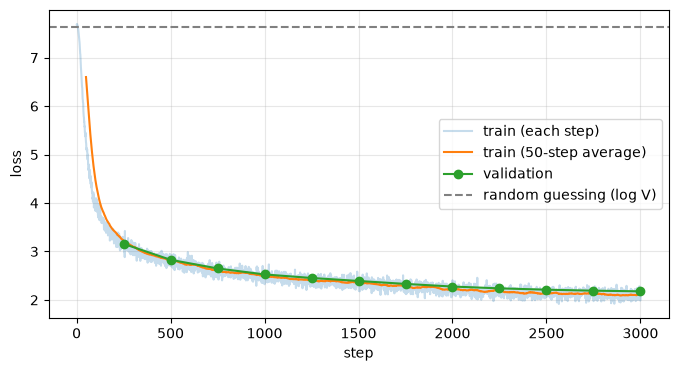

In [50]:
# Plot the loss curves
plt.figure(figsize=(8, 4))
steps_, losses_ = zip(*history["train"])
plt.plot(steps_, losses_, alpha=0.25, label="train (each step)")
w = 50
if len(losses_) > w:
    plt.plot(steps_[w - 1:], np.convolve(losses_, np.ones(w) / w, mode="valid"), label=f"train ({w}-step average)")
if history["val"]:
    plt.plot(*zip(*history["val"]), "o-", label="validation")
plt.axhline(math.log(model_cfg.vocab_size), ls="--", c="gray", label="random guessing (log V)")
plt.xlabel("step"); plt.ylabel("loss"); plt.legend(); plt.grid(alpha=0.3); plt.show()

### Let's read some stories

Try your own prompts, and play with `temperature` and `top_p`.

In [53]:
for prompt in ["Once upon a time", "Lily wanted to", "The dog was very"]:
    print(generate(model, tokenizer, prompt, max_new_tokens=150, temperature=0.8, top_p=0.95))
    print("-" * 80)

Once upon a time, there was a little boy named Tim. Tim was an ignorant about a big shelter. He loved to help people or talk to all the animals in the town. One day, he saw a big box. It was a tiny fairy! The fairy said, "Let's help the box to eat a red snack."
The sheep showed the phone to the box. Tim was so happy and said, "Thank you, little girl. Let's play together!" The small magazin was happy and thanked Tim. They played together every day, and Tim shared his secret with his friends.
<|endoftext|>
--------------------------------------------------------------------------------
Lily wanted to help Tom. She said, "I can help you find some food?" Lily nodded and said, "Okay, let's play some food." They played together all day and had lots of fun.
The next day, Lily went outside to play. She saw a big tree with a lot of pretty flowers. It was not pretty, but Lily was very happy. She hugged the tree and said, "Thank you, bird! I was a caterpillar!"
Lily and Max played with the new bi

In [54]:
prompt = "One day, Tom went to the park"
for temperature in [0.0, 0.5, 1.0, 1.5]:
    print(f"🌡️ temperature = {temperature}")
    print(generate(model, tokenizer, prompt, max_new_tokens=60, temperature=temperature))
    print()

🌡️ temperature = 0.0
One day, Tom went to the park with his mom. He saw a big tree with a big tree. The tree had a big tree with many leaves. Tom wanted to climb the tree, but he was too small.
Tom said to his mom, "Mom, can I climb the tree?" His mom said, "Yes,

🌡️ temperature = 0.5
One day, Tom went to the park with his mom. They saw a big tree with a big tree. The tree was very tall and tall. Tom wanted to touch the tree. He tried to climb the tree, but it was too high.
The tree said, "I can help you. I am sad." The tree wanted

🌡️ temperature = 1.0
One day, Tom went to the park. He saw a kick, brown dog. The dog wagged its tail, and the dog started to slip down the slide. It went through the slide, and it began to rain. Tom was so happy and jumped on the slide. The dog ran away after the slide, and the dog

🌡️ temperature = 1.5
One day, Tom went to the park and began to go stop. As playing, his favorite storm crazing? Fluffy bury braveer watched to zoom around, until he started to

**Things to notice:**
* With temperature 0 (greedy), the model often gets stuck repeating itself.
* With a high temperature, the text falls apart into nonsense.
* The validation loss tells you how good the model is *on stories it has never seen*. If the training loss keeps going down while the validation loss goes up, the model is **overfitting**: memorizing instead of learning.

---
# Part 8 — Where to go from here

**You've built a complete language model from scratch:** a BPE tokenizer, a Transformer with RoPE, RMSNorm and SwiGLU, cross-entropy, AdamW, a cosine schedule, gradient clipping, a training loop and a sampler. That's the same recipe as real LLMs.

### Getting better stories

The model improves with more training, more data and more parameters, roughly in that order of ease:

1. **Train longer.** Set `max_steps` to 10,000 or more *before* starting a fresh run. The cosine schedule is tied to `max_steps`, so changing it mid-run gives you a slightly odd schedule (it still works). Leave it running over lunch or overnight.
2. **More data.** Our ~5M tokens get repeated many times in a long run. The cell below streams the first 100 MB of the *real* TinyStories training set (no need to download all 2 GB) and makes it the new training data.
3. **A bigger model.** For example `ModelConfig(d_model=256, num_layers=6, num_heads=8, d_ff=704, context_length=256)` is about 6M parameters. It's noticeably better, but several times slower per step.

In [55]:
GET_MORE_DATA = False   # set to True and run this cell (takes a few minutes)
MORE_DATA_MB = 100

if GET_MORE_DATA:
    path = os.path.join(DATA_DIR, f"tinystories_train_{MORE_DATA_MB}MB_{VOCAB_SIZE}.npy")
    if not os.path.exists(path):
        url = "https://huggingface.co/datasets/roneneldan/TinyStories/resolve/main/TinyStoriesV2-GPT4-train.txt"
        print(f"Streaming the first {MORE_DATA_MB} MB of the TinyStories training set...")
        with urllib.request.urlopen(url) as response:
            text = response.read(MORE_DATA_MB * 1_000_000).decode("utf-8", errors="ignore")
        text = text[: text.rfind("<|endoftext|>")]   # cut at the last complete story
        print("Tokenizing (this takes a minute or two)...")
        np.save(path, np.array(tokenizer.encode(text), dtype=np.uint16))
    train_ids = np.load(path)
    print(f"New training set: {len(train_ids):,} tokens. Now re-create the model (Part 7) and train!")

### Experiments to try 

Change one thing at a time, train for the same number of steps, and compare the validation losses:

* **Learning rate sweep:** try `max_lr` = 1e-3, 3e-3, 1e-2 and 3e-2. Where does training become unstable or diverge?
* **No position information ("NoPE"):** run the code below, then re-run the cell that creates the model in Part 7, and train. (The model looks up `RoPE`, `RMSNorm`, etc. when it's *created*, so redefining them is enough.) How much worse is the model? Causal language models can still learn *some* position information without it!
  ```python
  class NoRoPE(nn.Module):
      def __init__(self, *args, **kwargs): super().__init__()
      def forward(self, x, token_positions): return x
  RoPE = NoRoPE
  ```
* **No normalization:** replace `RMSNorm` with a layer that returns its input unchanged. Does training still work at the same learning rate?
* **Post-norm:** change the block to `x = RMSNorm(x + sublayer(x))`, like the original Transformer.
* **SiLU instead of SwiGLU:** use `w2(silu(w1(x)))` with `d_ff = 4 × d_model`, so the parameter count roughly matches.
* **Debugging tip:** if you ever change the model and aren't sure it's correct, try to *overfit a single batch*. Train on the same `x, y` over and over. A correct model drives the loss close to zero quickly.
